--- Generating Synthetic E-commerce Data ---
Generated 5000 transactions for 500 unique customers.

--- Calculating RFM Metrics ---
            Recency  Frequency  Monetary
CustomerID                              
CUST-0001        41         11    313.07
CUST-0002        10          9    498.43
CUST-0003        30          8    458.45
CUST-0004        13          8    613.16
CUST-0005         7          9    328.68 

--- Ranking and Segmenting Customers ---
Segment
Average / Mid-Tier    125
Lost / Hibernating     97
Loyal Customers        85
Champions              70
Recent New Users       68
Can't Lose Them        55
Name: count, dtype: int64 

--- Segment Aggregations ---
                   Recency Frequency Monetary      
                      mean      mean     mean count
Segment                                            
Average / Mid-Tier    38.9       9.5    393.3   125
Can't Lose Them       58.6      13.1    677.7    55
Champions              9.5      13.6    827.0    70
Lost 

C:\Users\lab812-05.LABORATORIUM\AppData\Local\Temp\1\ipykernel_4484\3494788818.py:128: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=rfm, x='Segment', order=rfm['Segment'].value_counts().index, palette='viridis')


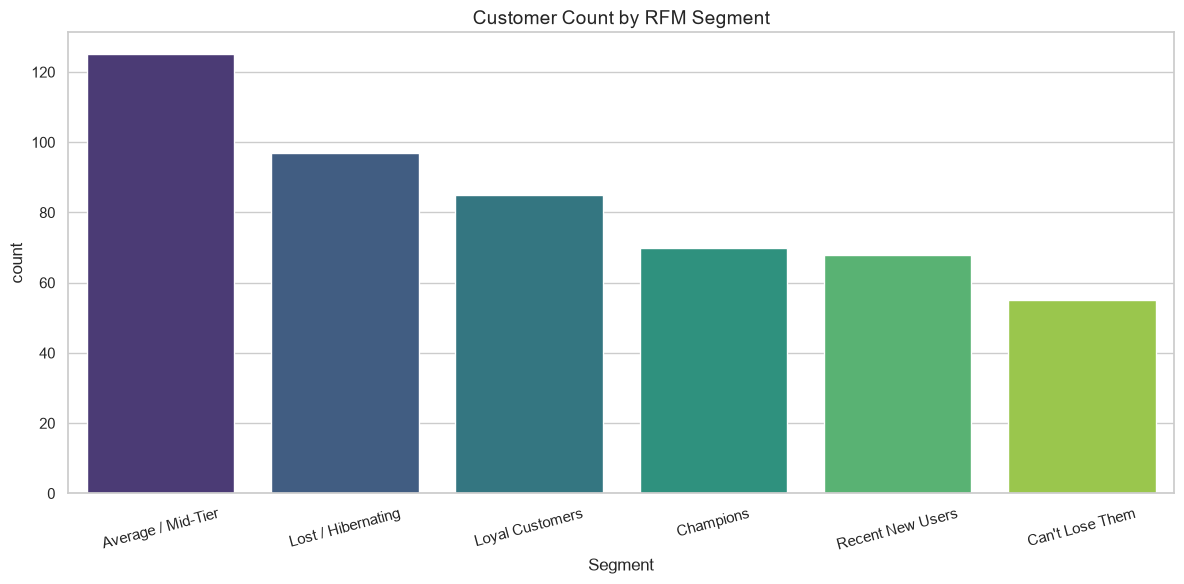

In [2]:
import numpy as np
import pandas as pd
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. GENERATE SYNTHETIC TRANSACTION DATA
# ==========================================
print("--- Generating Synthetic E-commerce Data ---")
np.random.seed(42)
num_customers = 500
num_transactions = 5000

# Create a baseline of customer IDs
customer_ids = [f"CUST-{str(i).zfill(4)}" for i in range(1, num_customers + 1)]

# Generate realistic transaction dates over the last year
end_date = datetime(2026, 11, 22)  # Current simulated date
start_date = end_date - timedelta(days=365)
date_range = [start_date + timedelta(days=int(i)) for i in range(365)]

# Assign unique behaviors to customers (some buy often, some spend a lot, some are inactive)
customer_profiles = {
    cid: {
        "freq_weight": np.random.exponential(scale=5),
        "spend_mu": np.random.normal(loc=50, scale=20),
    }
    for cid in customer_ids
}

# Generate individual transaction rows
tx_data = []
for _ in range(num_transactions):
    cust = np.random.choice(customer_ids)
    profile = customer_profiles[cust]
    
    # Date selection heavily weighted by frequency weight
    tx_date = np.random.choice(date_range)
    # Ensure monetary values are strictly positive
    tx_amount = max(5.0, round(np.random.normal(profile["spend_mu"], scale=15), 2))
    
    tx_data.append([cust, tx_date, tx_amount])

df_transactions = pd.DataFrame(tx_data, columns=["CustomerID", "TransactionDate", "Amount"])
print(f"Generated {df_transactions.shape[0]} transactions for {num_customers} unique customers.\n")


# ==========================================
# 2. CALCULATE RFM METRICS
# ==========================================
print("--- Calculating RFM Metrics ---")
# Snapshot date setup (usually day after last transaction)
snapshot_date = end_date + timedelta(days=1)

# Group transactions per customer
rfm = df_transactions.groupby('CustomerID').agg({
    'TransactionDate': lambda x: (snapshot_date - x.max()).days, # Recency
    'CustomerID': 'count',                                       # Frequency
    'Amount': 'sum'                                              # Monetary Value
})

# Rename columns
rfm.rename(columns={
    'TransactionDate': 'Recency',
    'CustomerID': 'Frequency',
    'Amount': 'Monetary'
}, inplace=True)

print(rfm.head(), "\n")


# ==========================================
# 3. SEGMENTATION USING QUANTILES
# ==========================================
print("--- Ranking and Segmenting Customers ---")
# Divide into quintiles (1 to 5)
# For Recency: lower is better (more recent), so labels are reversed
r_labels = range(5, 0, -1)
f_labels = range(1, 6)
m_labels = range(1, 6)

rfm['R'] = pd.qcut(rfm['Recency'], q=5, labels=r_labels)
rfm['F'] = pd.qcut(rfm['Frequency'].rank(method='first'), q=5, labels=f_labels)
rfm['M'] = pd.qcut(rfm['Monetary'], q=5, labels=m_labels)

# Concatenate RFM quartile scores to create an RFM Score (e.g., '555')
rfm['RFM_Score'] = rfm['R'].astype(str) + rfm['F'].astype(str) + rfm['M'].astype(str)

# Map scores to strategic segments
def assign_segment(df):
    r, f, m = int(df['R']), int(df['F']), int(df['M'])
    
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 3 and m >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'Recent New Users'
    elif r <= 2 and f >= 4:
        return 'Can\'t Lose Them'
    elif r <= 2 and f <= 2:
        return 'Lost / Hibernating'
    else:
        return 'Average / Mid-Tier'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)
print(rfm['Segment'].value_counts(), "\n")


# ==========================================
# 4. EXPLORATORY DATA ANALYSIS (EDA) VISUALS
# ==========================================
# Summary statistics per segment
segment_summary = rfm.groupby('Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(1)
print("--- Segment Aggregations ---")
print(segment_summary)

# Setup plotting style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Plot 1: Customer Segments Distribution
sns.countplot(data=rfm, x='Segment', order=rfm['Segment'].value_counts().index, palette='viridis')
plt.title('Customer Count by RFM Segment', fontsize=14)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()
